In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from langchain_deepseek import ChatDeepSeek

In [2]:
load_dotenv()

True

In [3]:
model = llm = ChatDeepSeek(model="deepseek-chat")

In [4]:
class FeedBack(BaseModel):
    
    sentiment:Literal['positive','negative']=Field(description='sentiment on review')

In [5]:
class WhyNegative(BaseModel):
    issue_type: Literal["UX", "Performance", "Bug", "Support", "Other"] = Field(description='The category of issue mentioned in the review')
    tone: Literal["angry", "frustrated", "disappointed", "calm"] = Field(description='The emotional tone expressed by the user')
    urgency: Literal["low", "medium", "high"] = Field(description='How urgent or critical the issue appears to be')

In [6]:
structured_model = model.with_structured_output(FeedBack, method="json_mode")
structured_model2 = model.with_structured_output(WhyNegative, method="json_mode")

In [7]:
prompt = "What is the sentiment of the following review in json format - The software too good"
result = structured_model.invoke(prompt)
print(result.sentiment)

positive


In [9]:
class ReviewSatae(TypedDict):
    review:str
    sentiment:Literal['positive','negative']
    diagnosis:dict
    response:str
    

In [10]:
def find_statement(state: ReviewSatae): 
    prompt = f"""
    For the following review find out the sentiment
    and return the result as JSON.

    Review:
    {state["review"]}
    """

    sentiment = structured_model.invoke(prompt)

    return {'sentiment': sentiment.sentiment}

In [11]:
def check_sentiment(state: ReviewSatae)-> Literal['positive_res','run_diagnosis']:
    if state['sentiment']=='positive':
        return 'positive_res'
    else:
        return 'run_diagnosis'

In [12]:
def positive_res(state: ReviewSatae):
    prompt=f"""Write a warm thank-you message in response to this review:
    \n\n\"{state['review']}\"\n
    Also, kindly ask the user to leave feedback on our website."""
    
    res=model.invoke(prompt)
    
    return {'response':res.content}



In [14]:
def run_diagnosis(state: ReviewSatae):
    prompt = f"""
    Diagnose this negative review.

    Review:
    {state['review']}

    Return the diagnosis as JSON.

    The issue_type MUST be exactly one of:
    UX, Performance, Bug, Support, Other.

    The tone MUST be exactly one of:
    angry, frustrated, disappointed, calm.

    The urgency MUST be exactly one of:
    low, medium, high.
    """
    res=structured_model2.invoke(prompt)
    
    return {'diagnosis':res.model_dump()}
     


In [15]:
def negative_res(state:ReviewSatae):
    diagnosis=state['diagnosis']
    
    prompt= f"""You are a support assistant.
           The user had a '{diagnosis['issue_type']}' issue, sounded '{diagnosis['tone']}', and marked urgency as '{diagnosis['urgency']}'.
           Write an empathetic, helpful resolution message.
           """
    res=model.invoke(prompt).content
    return {'response':res}


In [16]:
graph=StateGraph(ReviewSatae)
graph.add_node('find_statement',find_statement)
graph.add_node('positive_res',positive_res)
graph.add_node('run_diagnosis',run_diagnosis)
graph.add_node('negative_res',negative_res)


graph.add_edge(START,'find_statement')

graph.add_conditional_edges('find_statement',check_sentiment)

graph.add_edge('positive_res',END)
graph.add_edge('run_diagnosis','negative_res')
graph.add_edge('negative_res',END)


workflow=graph.compile()

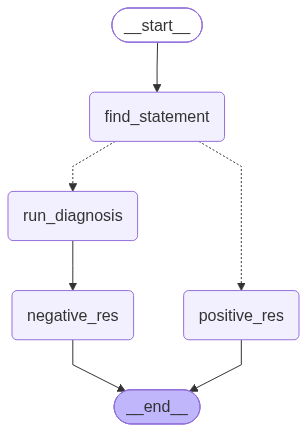

In [17]:
workflow

In [19]:
user_toold={ 'review': "wow!its good web"
}
workflow.invoke(user_toold)

{'review': 'wow!its good web',
 'sentiment': 'positive',
 'response': 'Here are a few options, ranging from short and sweet to a bit more personal. Choose the one that best fits your brand\'s tone.\n\n**Option 1: Short & Sweet (Best for a quick reply)**\n> Thank you so much for the kind words! We\'re thrilled to hear you like the website. If you have a moment, we\'d really appreciate it if you could leave this feedback on our site as well. Thanks again!\n\n**Option 2: Professional & Warm**\n> We\'re so glad you\'re enjoying the web experience! It means a lot to us that you took the time to share your positive impression. If you get a chance, we\'d love for you to post this review on our website, too—it helps others find us. Thanks for your support!\n\n**Option 3: Enthusiastic & Personal**\n> Wow, thank you so much! We\'re really happy you like the design and functionality of our site. Your positive feedback truly makes our day. If you have a spare minute, would you mind leaving a quick